Задание 1

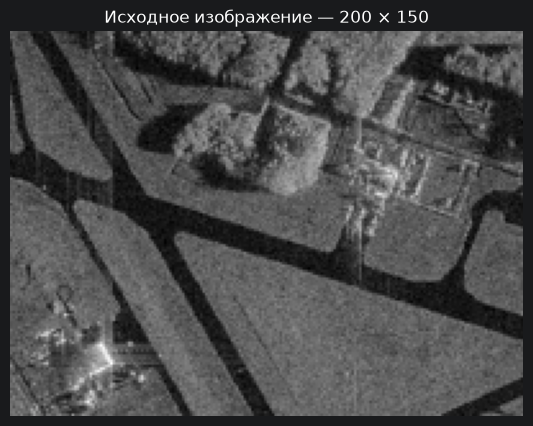

In [9]:
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

sar_path = Path('sar_1 (1).jpg')
if not sar_path.exists():
    raise FileNotFoundError(sar_path)

sar_color = cv2.imread(str(sar_path))
if sar_color is None:
    raise ValueError(f'Не удалось открыть {sar_path}')

sar_gray = cv2.cvtColor(sar_color, cv2.COLOR_BGR2GRAY)
sar_gray = cv2.resize(sar_gray, (0, 0), fx=0.5, fy=0.5)

plt.figure(figsize=(8, 5))
plt.imshow(sar_gray, cmap='gray')
plt.title(f'Исходное изображение — {sar_gray.shape[1]} × {sar_gray.shape[0]}')
plt.axis('off')
plt.show()

In [10]:
def grow_region(gray, seed, threshold, criterion='mean'):
    height, width = gray.shape
    sy, sx = seed
    if not (0 <= sy < height and 0 <= sx < width):
        raise ValueError(f'Точка {seed} вне изображения {gray.shape}')
    if criterion not in ('mean', 'seed'):
        raise ValueError("criterion должен быть 'mean' или 'seed'")

    selected = np.zeros((height, width), dtype=np.uint8)
    selected[sy, sx] = 1
    pending = deque([(sy, sx)])

    region_sum = float(gray[sy, sx])
    region_size = 1
    seed_intensity = float(gray[sy, sx])

    while pending:
        y, x = pending.popleft()
        for ny, nx in ((y-1, x), (y+1, x), (y, x-1), (y, x+1)):
            if not (0 <= ny < height and 0 <= nx < width):
                continue
            if selected[ny, nx]:
                continue

            reference = region_sum / region_size if criterion == 'mean' else seed_intensity
            intensity = float(gray[ny, nx])
            if abs(intensity - reference) <= threshold:
                selected[ny, nx] = 1
                pending.append((ny, nx))
                region_sum += intensity
                region_size += 1

    return selected * 255

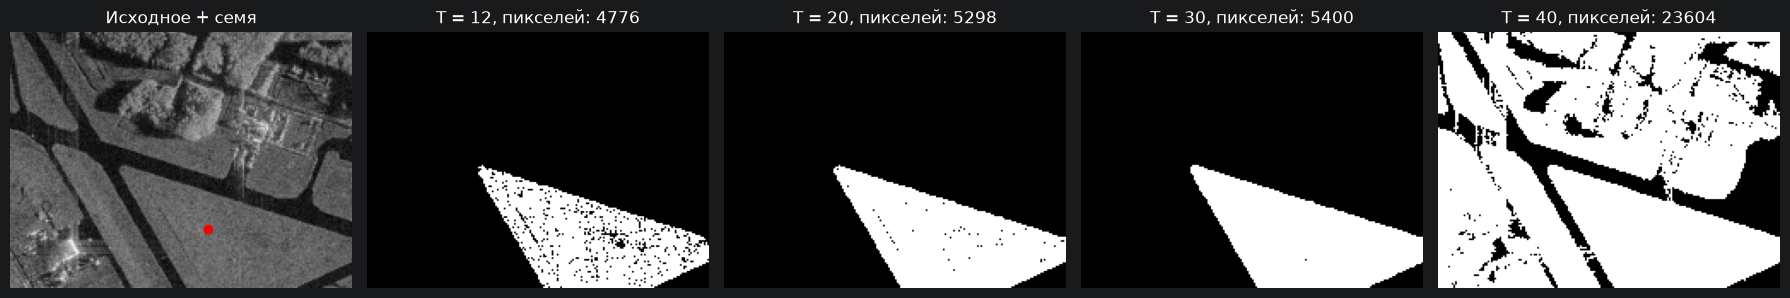

In [11]:
seed_point = (115, 115)
thresholds = [12, 20, 30, 40]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(sar_gray, cmap='gray')
axes[0].scatter(seed_point[1], seed_point[0], color='red', s=35)
axes[0].set_title('Исходное + семя')

for ax, T in zip(axes[1:], thresholds):
    result = grow_region(sar_gray, seed_point, T, criterion='mean')
    ax.imshow(result, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'T = {T}, пикселей: {np.count_nonzero(result)}')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

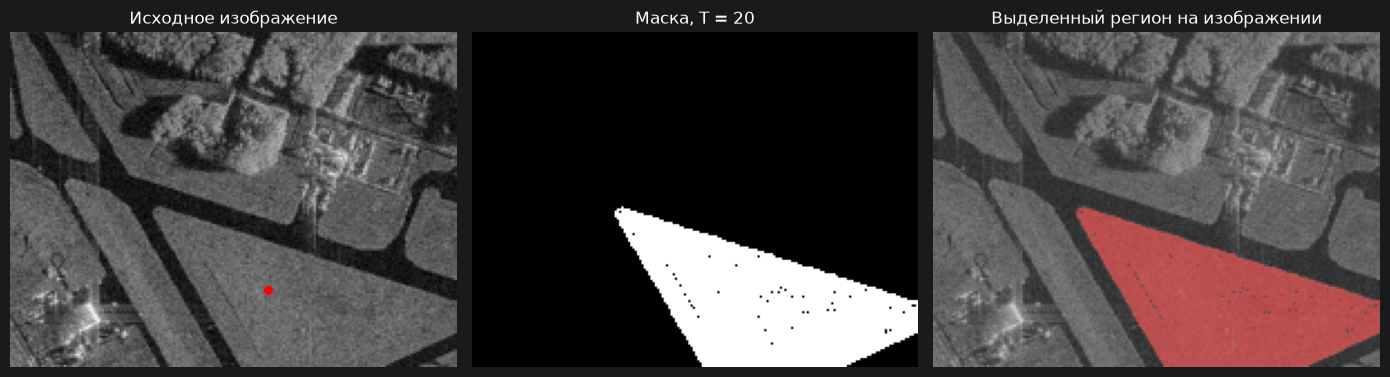

Площадь выделенного региона: 5298 пикселей


In [12]:
best_T = 20
lawn_mask = grow_region(sar_gray, seed_point, best_T, criterion='mean')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(sar_gray, cmap='gray')
axes[0].scatter(seed_point[1], seed_point[0], color='red', s=30)
axes[0].set_title('Исходное изображение')
axes[1].imshow(lawn_mask, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f'Маска, T = {best_T}')

highlight = cv2.cvtColor(sar_gray, cv2.COLOR_GRAY2RGB)
highlight[lawn_mask > 0] = (
    0.45 * highlight[lawn_mask > 0] + 0.55 * np.array([255, 60, 60])
).astype(np.uint8)
axes[2].imshow(highlight)
axes[2].set_title('Выделенный регион на изображении')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
print('Площадь выделенного региона:', np.count_nonzero(lawn_mask), 'пикселей')

Задание 2

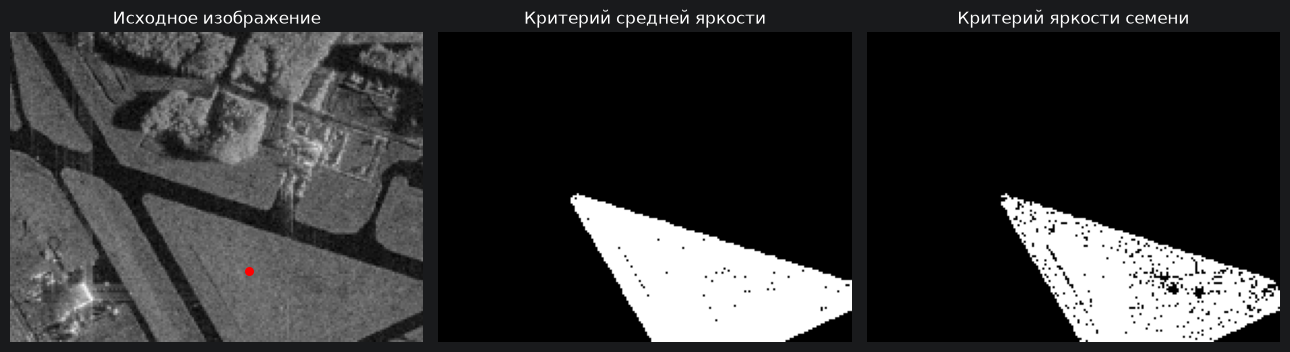

Площадь региона (средняя яркость): 5298 пикселей
Площадь региона (яркость начальной точки): 4837 пикселей
Совпадение масок (IoU): 0.912


In [13]:
mask_mean = grow_region(sar_gray, seed_point, best_T, criterion='mean')
mask_seed = grow_region(sar_gray, seed_point, best_T, criterion='seed')

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(sar_gray, cmap='gray')
axes[0].scatter(seed_point[1], seed_point[0], color='red', s=30)
axes[0].set_title('Исходное изображение')
axes[1].imshow(mask_mean, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Критерий средней яркости')
axes[2].imshow(mask_seed, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Критерий яркости семени')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

n_mean = np.count_nonzero(mask_mean)
n_seed = np.count_nonzero(mask_seed)
intersection = np.count_nonzero((mask_mean > 0) & (mask_seed > 0))
union = np.count_nonzero((mask_mean > 0) | (mask_seed > 0))
print(f'Площадь региона (средняя яркость): {n_mean} пикселей')
print(f'Площадь региона (яркость начальной точки): {n_seed} пикселей')
print(f'Совпадение масок (IoU): {intersection / union:.3f}' if union else 'Обе маски пусты')

Задание 3

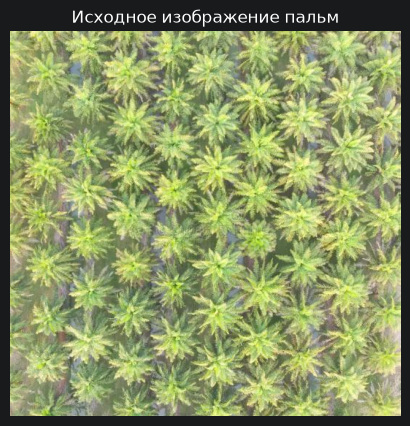

In [14]:
palm_path = Path('palm_1.JPG')
if not palm_path.exists():
    raise FileNotFoundError(palm_path)

palms = cv2.imread(str(palm_path))
if palms is None:
    raise ValueError(f'Не удалось прочитать {palm_path}')

palm_gray = cv2.cvtColor(palms, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(7, 5))
plt.imshow(cv2.cvtColor(palms, cv2.COLOR_BGR2RGB))
plt.title('Исходное изображение пальм')
plt.axis('off')
plt.show()

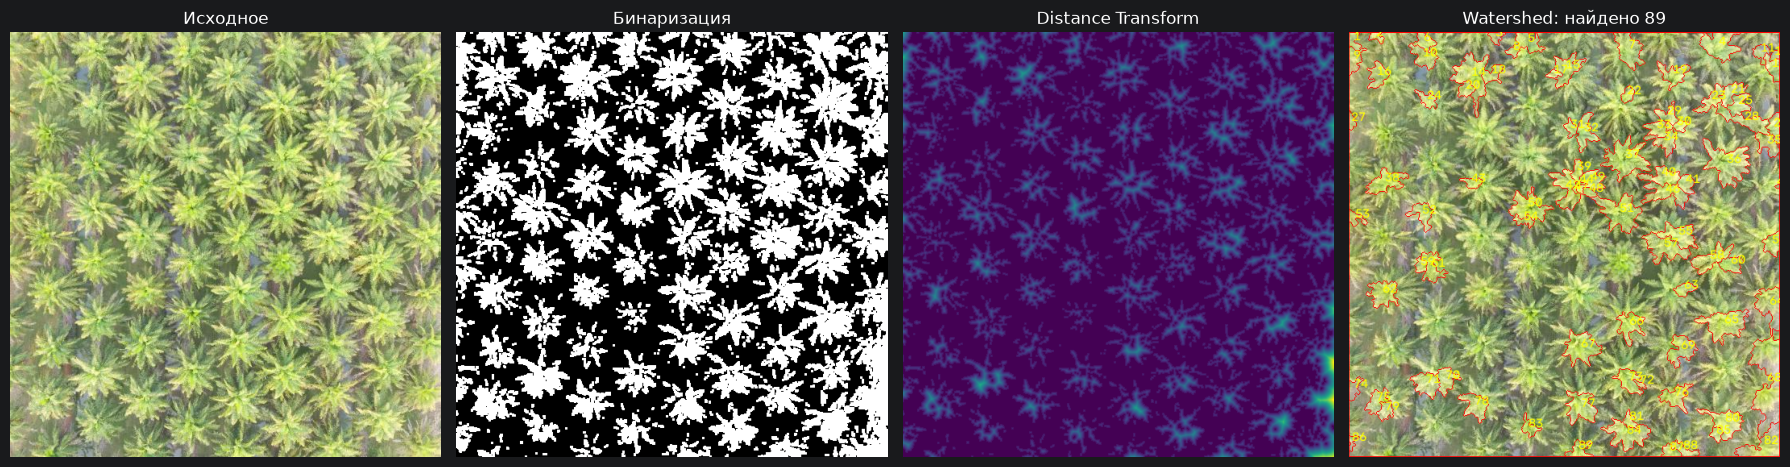

Найдено объектов-кандидатов: 89


In [15]:

invert_binary = False
peak_fraction = 0.35
min_region_area = 15

binary_mode = cv2.THRESH_BINARY_INV if invert_binary else cv2.THRESH_BINARY
_, binary = cv2.threshold(palm_gray, 0, 255, binary_mode + cv2.THRESH_OTSU)

kernel = np.ones((3, 3), dtype=np.uint8)
cleaned = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
sure_background = cv2.dilate(cleaned, kernel, iterations=2)

distance = cv2.distanceTransform(cleaned, cv2.DIST_L2, 5)
_, sure_foreground = cv2.threshold(distance, peak_fraction * distance.max(), 255, cv2.THRESH_BINARY)
sure_foreground = sure_foreground.astype(np.uint8)
unknown = cv2.subtract(sure_background, sure_foreground)

_, markers = cv2.connectedComponents(sure_foreground)
markers = markers + 1
markers[unknown > 0] = 0
markers = cv2.watershed(palms.copy(), markers.astype(np.int32))

areas = {int(label): int(np.count_nonzero(markers == label))
         for label in np.unique(markers) if label > 1}
valid_labels = [label for label, area in areas.items() if area >= min_region_area]

annotated = cv2.cvtColor(palms, cv2.COLOR_BGR2RGB)
annotated[markers == -1] = [255, 0, 0]
for index, label in enumerate(valid_labels, 1):
    ys, xs = np.where(markers == label)
    cy, cx = int(ys.mean()), int(xs.mean())
    cv2.putText(annotated, str(index), (cx, cy), cv2.FONT_HERSHEY_SIMPLEX,
                0.5, (255, 255, 0), 1, cv2.LINE_AA)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(cv2.cvtColor(palms, cv2.COLOR_BGR2RGB))
axes[0].set_title('Исходное')
axes[1].imshow(cleaned, cmap='gray')
axes[1].set_title('Бинаризация')
axes[2].imshow(distance, cmap='viridis')
axes[2].set_title('Distance Transform')
axes[3].imshow(annotated)
axes[3].set_title(f'Watershed: найдено {len(valid_labels)}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
print('Найдено объектов-кандидатов:', len(valid_labels))